In [1]:
# Standard library
import warnings
warnings.filterwarnings("ignore")

# Data
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Modeling
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# Persistence
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [5]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "duplicates": [df.duplicated().sum()] * df.shape[1],
    "dtype": df.dtypes,
})
quality

,missing,duplicates,dtype
MedInc,0,0,float64
HouseAge,0,0,float64
AveRooms,0,0,float64
AveBedrms,0,0,float64
Population,0,0,float64
AveOccup,0,0,float64
Latitude,0,0,float64
Longitude,0,0,float64
MedHouseVal,0,0,float64


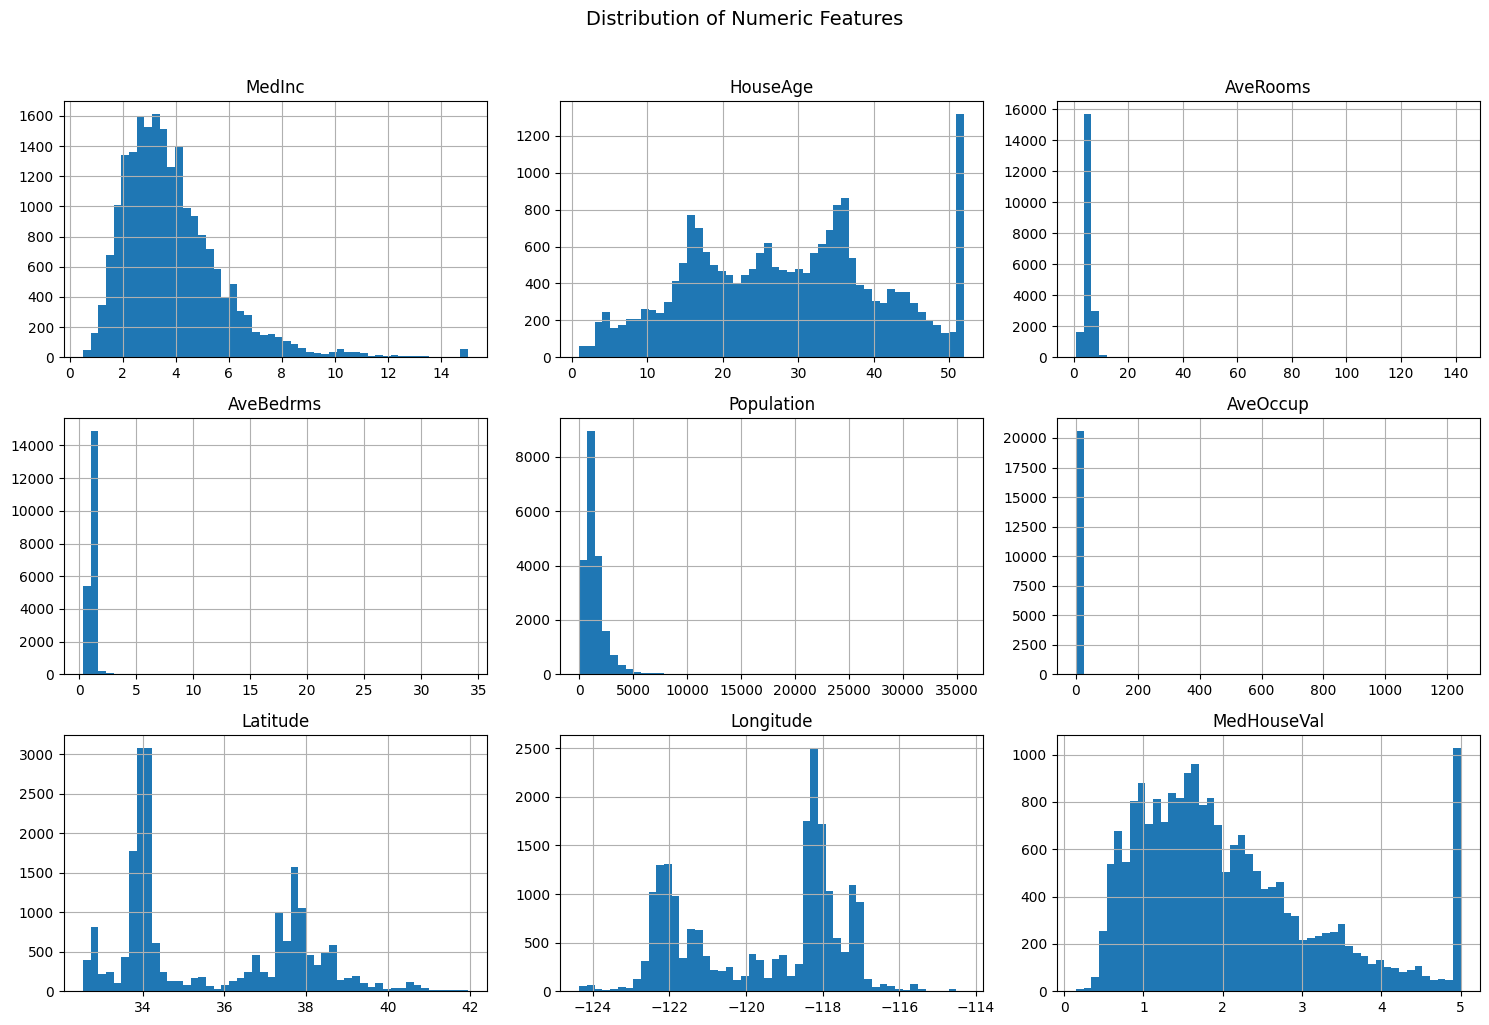

In [6]:
df.hist(figsize=(15, 10), bins=50)
plt.suptitle("Distribution of Numeric Features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

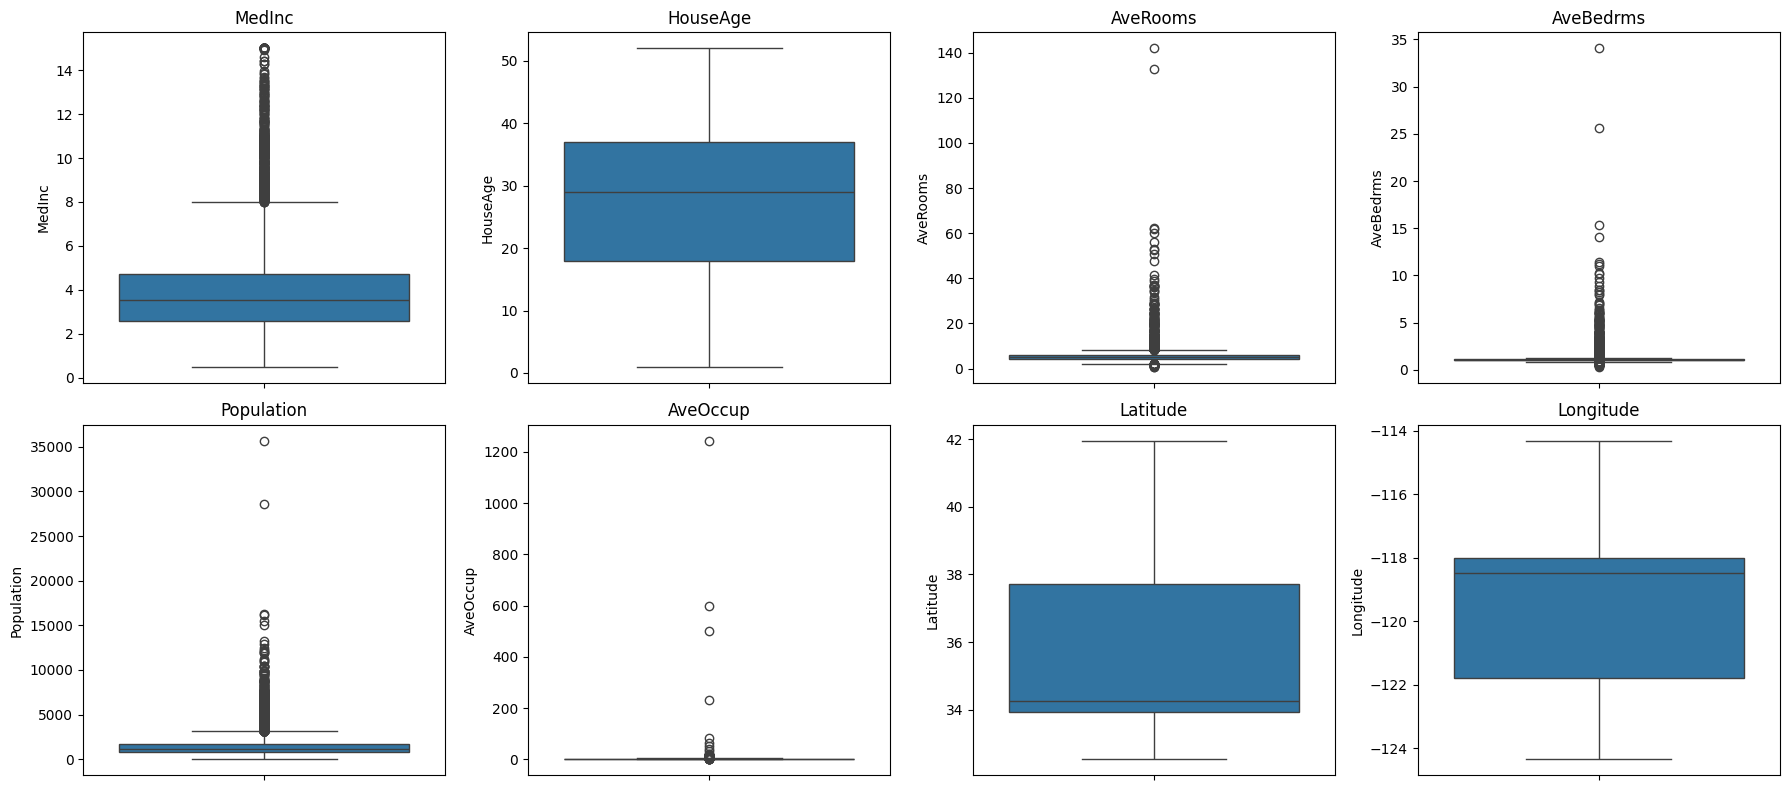

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

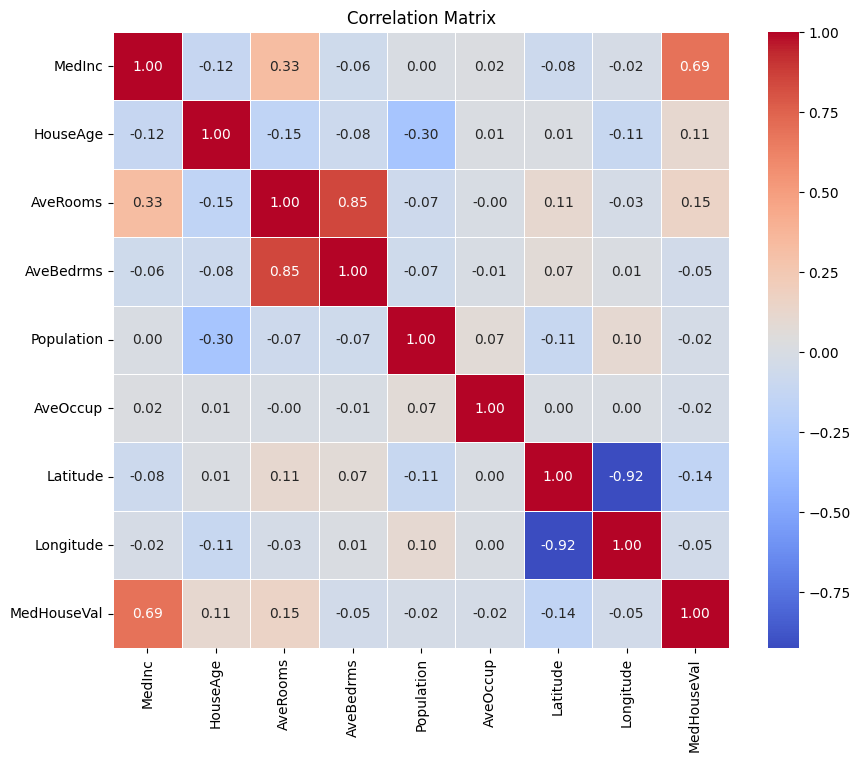

,MedHouseVal
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


In [8]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, square=True)
plt.title("Correlation Matrix")
plt.show()

corr["MedHouseVal"].drop("MedHouseVal").sort_values(ascending=False)

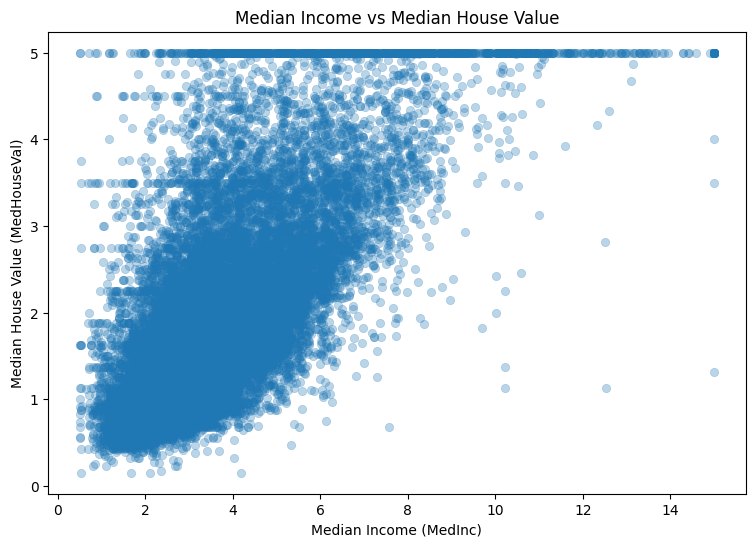

In [9]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.3, edgecolor=None)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (MedHouseVal)")
plt.show()

In [10]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Train: (16512, 8)  Test: (4128, 8)


In [11]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """Fit model, return train/test MAE & RMSE, and predictions."""
    model.fit(X_tr, y_tr)
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    return {
        "Model": name,
        "MAE Train":  mean_absolute_error(y_tr, y_tr_pred),
        "MAE Test":   mean_absolute_error(y_te, y_te_pred),
        "RMSE Train": np.sqrt(mean_squared_error(y_tr, y_tr_pred)),
        "RMSE Test":  np.sqrt(mean_squared_error(y_te, y_te_pred)),
        "_model": model,
    }

In [12]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])
lr_result = evaluate_model("Linear Regression", lr_pipeline, X_train, y_train, X_test, y_test)
print({k: v for k, v in lr_result.items() if k != "_model"})

{'Model': 'Linear Regression', 'MAE Train': 0.5286283596581935, 'MAE Test': 0.5332001304956565, 'RMSE Train': np.float64(0.7196757085831575), 'RMSE Test': np.float64(0.7455813830127761)}


In [13]:
dt_result = evaluate_model(
    "Decision Tree (default)",
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test,
)

dt_limited_result = evaluate_model(
    "Decision Tree (max_depth=10)",
    DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test,
)

In [14]:
rf_result = evaluate_model(
    "Random Forest (baseline)",
    RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, y_train, X_test, y_test,
)

In [15]:
results = pd.DataFrame([
    {k: v for k, v in r.items() if k != "_model"}
    for r in [lr_result, dt_result, dt_limited_result, rf_result]
])
results.sort_values("MAE Test").reset_index(drop=True)

,Model,MAE Train,MAE Test,RMSE Train,RMSE Test
0,Random Forest (baseline),1.220567e-01,0.327543,1.879562e-01,0.505340
1,Decision Tree (max_depth=10),3.191957e-01,0.433203,4.699636e-01,0.644568
2,Decision Tree (default),4.593655e-17,0.454679,3.218326e-16,0.703729
3,Linear Regression,5.286284e-01,0.533200,7.196757e-01,0.745581


In [16]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV MAE: 0.3385773263055081


In [17]:
best_model = grid_search.best_estimator_
tuned_result = evaluate_model("Random Forest (tuned)", best_model,
                              X_train, y_train, X_test, y_test)
print({k: v for k, v in tuned_result.items() if k != "_model"})

{'Model': 'Random Forest (tuned)', 'MAE Train': 0.14407531322820236, 'MAE Test': 0.32599704472621904, 'RMSE Train': np.float64(0.23446348609764894), 'RMSE Test': np.float64(0.504018445179664)}


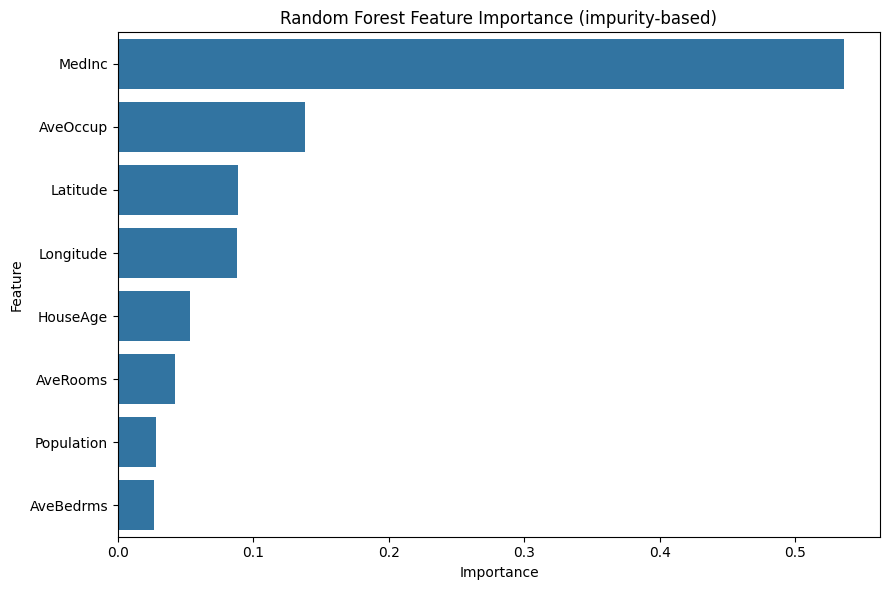

,Feature,Importance
0,MedInc,0.535586
5,AveOccup,0.138016
6,Latitude,0.088314
7,Longitude,0.087840
1,HouseAge,0.053332
2,AveRooms,0.042279
4,Population,0.028046
3,AveBedrms,0.026587


In [18]:
fi_impurity = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_,
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=fi_impurity, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance (impurity-based)")
plt.tight_layout()
plt.show()
fi_impurity

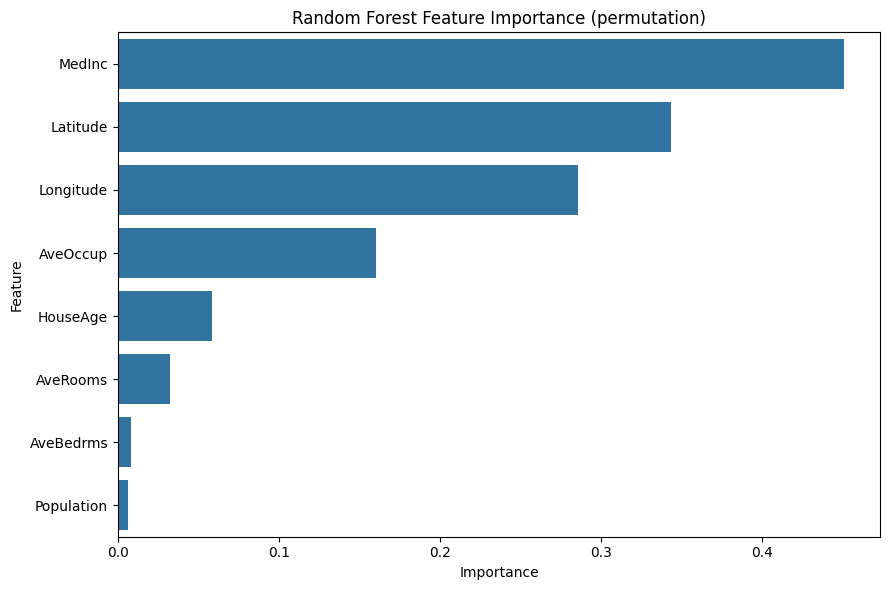

,Feature,Importance,Std
0,MedInc,0.450479,0.007267
6,Latitude,0.343211,0.006142
7,Longitude,0.285546,0.004456
5,AveOccup,0.160167,0.003259
1,HouseAge,0.058112,0.002365
2,AveRooms,0.032247,0.001767
3,AveBedrms,0.007955,0.000918
4,Population,0.006401,0.000898


In [19]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1,
)

fi_perm = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=fi_perm, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance (permutation)")
plt.tight_layout()
plt.show()
fi_perm

In [20]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    best_model, X_train, y_train,
    cv=kf,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    n_jobs=-1,
)

mae_scores  = -cv_results["test_MAE"]
rmse_scores = -cv_results["test_RMSE"]

print(f"MAE  per fold: {np.round(mae_scores, 4)}")
print(f"MAE  mean={mae_scores.mean():.4f}  std={mae_scores.std():.4f}")
print(f"RMSE per fold: {np.round(rmse_scores, 4)}")
print(f"RMSE mean={rmse_scores.mean():.4f}  std={rmse_scores.std():.4f}")

MAE  per fold: [0.3427 0.3273 0.3284 0.3352 0.332 ]
MAE  mean=0.3331  std=0.0055
RMSE per fold: [0.524  0.4962 0.5027 0.5239 0.5015]
RMSE mean=0.5097  std=0.0119


In [22]:
artifact = {
    "model": best_model,
    "feature_names": X_train.columns.tolist(),
    "target_name": "MedHouseVal",
}
joblib.dump(artifact, "california_housing_model.joblib")

# Load & sanity-check
loaded = joblib.load("california_housing_model.joblib")
print("Sample prediction:", loaded["model"].predict(X_test.iloc[:5]))
print("Actual           :", y_test.iloc[:5].values)

Sample prediction: [0.49362085 0.75199252 4.88082634 2.55531125 2.28225102]
Actual           : [0.477   0.458   5.00001 2.186   2.78   ]


In [23]:
import pandas as pd

# Data input baru yang telah disesuaikan dengan angka realistis
input_prediksi = {
  "MedInc": 3.87,     # Pendapatan menengah
  "HouseAge": 28.0,    # Usia rumah
  "AveRooms": 5.4,     # Rata-rata jumlah kamar
  "AveBedrms": 1.1,    # Rata-rata jumlah kamar tidur
  "Population": 1425.0, # Populasi area
  "AveOccup": 3.0,     # Rata-rata okupansi/penghuni
  "Latitude": 35.6,    # Garis lintang
  "Longitude": -119.5  # Garis bujur
}

# Mengonversi input ke DataFrame satu baris
df_input = pd.DataFrame([input_prediksi])

# Melakukan prediksi menggunakan model yang sudah dilatih sebelumnya
hasil_prediksi = loaded["model"].predict(df_input)[0]

# Menampilkan hasil prediksi
print("--- Parameter Input Prediksi ---")
for key, val in input_prediksi.items():
    print(f"{key}: {val}")

print("\n--- Hasil Prediksi ---")
print(f"Estimasi Nilai Rumah (MedHouseVal): ${hasil_prediksi * 100000:,.2f} (atau {hasil_prediksi:.4f} dalam satuan ratusan ribu USD)")

--- Parameter Input Prediksi ---
MedInc: 3.87
HouseAge: 28.0
AveRooms: 5.4
AveBedrms: 1.1
Population: 1425.0
AveOccup: 3.0
Latitude: 35.6
Longitude: -119.5

--- Hasil Prediksi ---
Estimasi Nilai Rumah (MedHouseVal): $85,456.30 (atau 0.8546 dalam satuan ratusan ribu USD)


## Conclusion

| Model                          | MAE Test | RMSE Test |
|--------------------------------|---------:|----------:|
| Linear Regression              |  ~0.533  |   ~0.746  |
| Decision Tree (default)        |  ~0.455  |   ~0.704  |
| Decision Tree (max_depth=10)   |  ~0.433  |   ~0.645  |
| Random Forest (baseline)       |  ~0.328  |   ~0.505  |
| Random Forest (tuned)          |  **~0.326** | **~0.504** |

**Key drivers:** `MedInc` dominates; then `Latitude` / `Longitude` / `AveOccup`.

**Stability:** 5-fold CV MAE ≈ 0.335 ± 0.005.

**Artifacts:** `california_housing_model.joblib` containing the model + metadata.

**Next steps:**
- Feature engineering (distance to coast, room/occupant ratios).
- Try gradient boosting (LightGBM / XGBoost).
- Residual analysis & calibration on high-value segment (near the 5.0 cap).
- Wrap into a `Pipeline` with preprocessing for full reproducibility.